In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize

In [2]:
df = pd.read_csv("../data/uk_clean.csv")
df["date"] = pd.to_datetime(df["date"])

df = df[(df["date"] >= "2020-03-01") & (df["date"] <= "2020-08-01")].copy()
df = df.reset_index(drop=True)

df["I_data"] = df["new_cases"].rolling(7).sum()
df = df.dropna().reset_index(drop=True)

t_data = np.arange(len(df))
I_data = df["I_data"].values

In [3]:
def sir(t, y, beta, gamma, N):
    S, I, R = y
    dS = -beta * S * I / N
    dI = beta * S * I / N - gamma * I
    dR = gamma * I
    return [dS, dI, dR]

In [4]:
def simulate(beta, gamma, N, I0, R0, t_eval):
    S0 = N - I0 - R0
    y0 = [S0, I0, R0]

    sol = solve_ivp(
        lambda t, y: sir(t, y, beta, gamma, N),
        (t_eval[0], t_eval[-1]),
        y0,
        t_eval=t_eval
    )
    return sol.y

In [5]:
N = 56_000_000
I0 = float(I_data[0])
R0 = 0.0

def loss(params):
    beta, gamma = params
    if beta <= 0 or gamma <= 0:
        return 1e20

    S, I, R = simulate(beta, gamma, N, I0, R0, t_data)
    return np.mean((I - I_data)**2)

In [6]:
res = minimize(
    loss,
    x0=[0.4, 1/7],
    bounds=[(1e-4, 2), (1e-4, 1)]
)

beta_hat, gamma_hat = res.x

print("beta:", beta_hat)
print("gamma:", gamma_hat)
print("R0:", beta_hat / gamma_hat)

beta: 1.0256903092597212
gamma: 1.0
R0: 1.0256903092597212


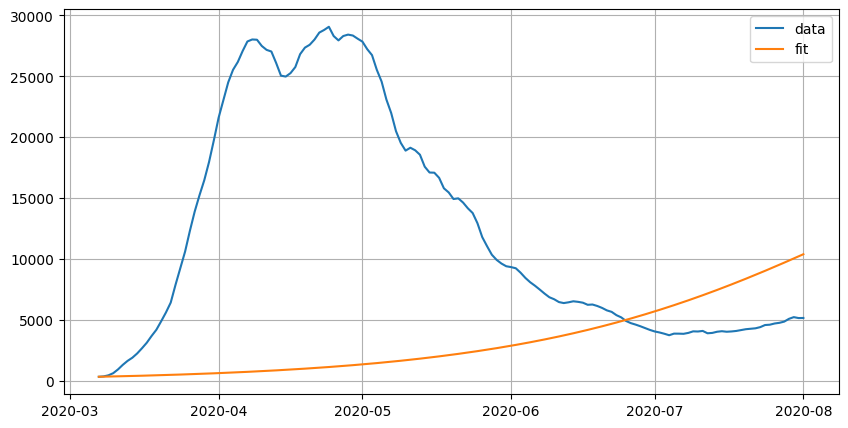

In [7]:
S, I_fit, R = simulate(beta_hat, gamma_hat, N, I0, R0, t_data)

plt.figure(figsize=(10,5))
plt.plot(df["date"], I_data, label="data")
plt.plot(df["date"], I_fit, label="fit")
plt.legend()
plt.grid()
plt.show()